<a href="https://colab.research.google.com/github/codesearth/XX_SuperSong_XX1000/blob/main/SuperSong1000.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
# ==============================================================================
# CELL 1: DOWNLOAD SONGS FROM GOOGLE DRIVE & IMPORT TOOLKITS. Naman
# ==============================================================================
# Plain English: Installs the Google Drive downloader (`gdown`) and downloads your
# entire folder of songs into `/content/SONG`.
!pip install -q gdown
!gdown --folder https://drive.google.com/drive/folders/1ykaqUKRiZsCOQDmnK_pGCRBvlNTcErrZ -O /content/SONG

import os                        # Works with folders and file paths
import gc                        # "Garbage Collector" - empties RAM trash so Colab never crashes!
import json                      # Reads and writes settings files (.json)
import glob                      # Searches folders for files
import hashlib                   # Turns peak pairs into 8-character barcode hashes for Group 2
import numpy as np               # Fast math calculator for audio number lists
import pandas as pd              # Creates clean spreadsheet tables (DataFrames) and .csv files
import matplotlib.pyplot as plt  # Draws waveforms, spectrograms, and histograms
import scipy.ndimage as ndimage  # Scans 2D spectrograms to find the brightest local dots ("peaks")
from scipy.spatial.distance import cosine  # Compares average pitch profiles for Group 2 Task 5
import soundfile as sf           # Quickly reads audio file properties (sample rate, duration)
import librosa                   # Main audio processing library
import librosa.display           # Draws audio waveforms and spectrograms
from IPython.display import display, Audio, HTML, clear_output  # Builds clean visual cards & audio players!
import ipywidgets as widgets     # Builds clickable dropdown menus, sliders, and buttons in Colab!

Retrieving folder contents
Processing file 1fLx55c5mxN4YbUyo5YGdd7jHlbSocppk 7 rings.wav
Processing file 1nzqEyevHDVUpJsgVvcSUiXX6EYkV60xf 7 Years.wav
Processing file 1D6Ys30MwLe-707vD8tVLyiE5P2iajlNE a thousand years.wav
Processing file 1cPWd3LP3ArTBxKfa-5OyKMhaXXcnm9yO Aria Math.wav
Processing file 1YI3I0945xfyAELXqSHQve6IExW3_aOHC Ariana Grande & The Weeknd - Love Me Harder (Lyrics) - RouxioMusic.wav
Processing file 1DwN0ZKOrztePuueF337BPId_xQvys4gX Billie Eilish - bad guy - BillieEilishVEVO.wav
Processing file 1_-yV-3G2p06wOnQfNETXmQQlgbasLVY- Blackbear - Idfc OFFICIAL VERSION - StrictlyHits.wav
Processing file 1btPOL_sH0E-z69VLhKANpRM65aEQcff- Britney Spears - Gimme More (Lyrics) - 7clouds Rock.wav
Processing file 1bbBtzFjdG6UDDQHEdX5LWGUxbNF_UOVp Broken Strings.wav
Processing file 1W7f_tVhTgmtuaIVT2m03kY1fVSIxtTk1 Call Me Maybe.wav
Processing file 1ofUXeRyJbv07OP5rEhjm3KAa8GewW9sJ Camila Cabello - Havana (Audio) ft. Young Thug - CamilaCabelloVEVO.wav
Processing file 1ivhUY44ehIS7

In [22]:
# ==============================================================================
# CELL 2: SMART SONG FINDER (FINDS ALL 40 SONGS) & GROUP 1 CORE FUNCTIONS. Naman
# ==============================================================================
# # Sonic Signatures: Group 1 (Audio Analysis)
#
# **Tasks**
# 1. Audio loading and waveform analysis
# 2. Spectrogram and window-size study
# 3. Spectral peak detection (constellation map)
#
# **Handover to Group 2**
# * `handover/<song>_peaks.csv` (one row per peak for EVERY song)
# * `handover/peak_config.json` (the exact settings used to make those peaks)
# * the reusable `get_peaks(y, sr)` function, so Group 2/3 can run the *same* extractor on query clips

# FIX: Search "/content/SONG" AND "/content/Songs" recursively (including all subfolders)
# and match ALL audio formats (.wav, .mp3, .flac, .ogg, .m4a), not just lowercase .wav!
AUDIO_EXTENSIONS = (".wav", ".mp3", ".flac", ".ogg", ".m4a")
SONG_PATHS = []
for root_folder in ["/content/SONG", "/content/Songs"]:
    if os.path.exists(root_folder):
        for root, _, files in os.walk(root_folder):
            for file in files:
                if file.lower().endswith(AUDIO_EXTENSIONS):
                    SONG_PATHS.append(os.path.join(root, file))

SONG_PATHS = sorted(list(set(SONG_PATHS)))
NAMES = [os.path.splitext(os.path.basename(p))[0] for p in SONG_PATHS]
SONG_MAP = dict(zip(NAMES, SONG_PATHS))  # Maps each clean song name -> its file path on disk

print(f"✅ Successfully discovered {len(SONG_PATHS)} audio files across your folder!")

TARGET_SR = 22050  # common sample rate for every song (22,050 snapshots per second)
OUT_DIR = "handover"

# Settings used for the final peak extraction (revisit after the Task 2 and Task 3 experiments).
FINAL_CFG = dict(
    n_fft=2048,            # window length in samples (~93 ms per slice)
    hop_length=512,        # step between windows in samples (~23 ms step forward)
    fmax=8000,             # ignore peaks above this frequency (Hz)
    freq_radius=10,        # a peak must be the maximum within +/- this many frequency bins
    time_radius=10,        # ... and within +/- this many time frames
    threshold_db=-40,      # ignore peaks quieter than this (dB relative to the loudest point)
    max_peaks_per_sec=None # optional cap on peaks per second (None = no cap)
)


# --- TASK 1 FUNCTIONS: AUDIO INSPECTION & LOADING ---

def inspect_audio(path):
    """Report the file's ORIGINAL properties, before any conversion.
    Plain English: Reads the song file's label (sample rate, mono/stereo channels, duration in seconds)
    without holding the gigantic audio wave in RAM.
    """
    try:
        info = sf.info(path)
        sr, channels, duration = info.samplerate, info.channels, info.duration
    except Exception:
        # Some formats (e.g. mp3 with an old libsndfile) are not readable by soundfile.
        y, sr = librosa.load(path, sr=None, mono=False, dtype=np.float32)
        channels = 1 if y.ndim == 1 else y.shape[0]
        duration = y.shape[-1] / sr
        del y
    return {
        "file": os.path.basename(path),
        "orig_sr": sr,
        "orig_channels": channels,
        "orig_duration_s": round(duration, 2),
    }


def load_audio(path, target_sr=TARGET_SR, normalize=True, offset=0.0, duration=None):
    """Reusable loader: mono, resampled to target_sr, peak-normalised to [-1, 1].

    Returns (y, sr). No plotting here, so Groups 2 and 3 can call it on any clip.
    Plain English: Converts any song to 1 channel (Mono), 22,050 snapshots/sec, and scales
    the volume so the loudest point is 1.0. Uses `float32` so it takes half the RAM!
    """
    y, sr = librosa.load(
        path, sr=target_sr, mono=True, offset=offset, duration=duration,
        res_type="soxr_hq", dtype=np.float32
    )
    if normalize and len(y) > 0:
        peak = np.max(np.abs(y))
        if peak > 0:
            y = y / peak
    return y, sr


def plot_waveform(y, sr, title="", ax=None):
    """Plain English: Plots Time (s) on the bottom vs. Volume (Amplitude) on the side."""
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 2.5))
    librosa.display.waveshow(y, sr=sr, ax=ax, alpha=0.8, color="royalblue")
    ax.set(title=title, xlabel="Time (s)", ylabel="Amplitude")


# --- TASK 2 FUNCTIONS: SPECTROGRAM & WINDOW-SIZE STUDY ---

def compute_spectrogram(y, n_fft, hop_length):
    """Magnitude STFT in dB, relative to the loudest point of THIS signal.

    Shape is (n_fft // 2 + 1 frequency bins, n_frames).
    Plain English: Slices the audio into overlapping windows of `n_fft` snapshots, separates
    low bass notes from high treble notes using the Fourier Transform (STFT), and converts the
    strength into Decibels (dB) where 0 dB is the brightest/loudest note in the clip.
    """
    D = librosa.stft(y, n_fft=n_fft, hop_length=hop_length, dtype=np.complex64)
    return librosa.amplitude_to_db(np.abs(D), ref=np.max)


def resolution_table(sr, n_fft_list, hop_length):
    """Time/frequency resolution implied by each window size.
    Plain English: Calculates the exact millisecond width and Hertz sharpness for each window size.
    """
    rows = []
    for n in n_fft_list:
        rows.append({
            "n_fft (Window Samples)": n,
            "Time Window (ms)": round(1000 * n / sr, 1),        # how much audio each column "sees": time resolution
            "Pitch Row Width (Hz)": round(sr / n, 1),           # spacing between frequency rows: frequency resolution
            "Step Size (ms)": round(1000 * hop_length / sr, 1),
            "Window Overlap (%)": round(100 * (1 - hop_length / n), 1),
        })
    return pd.DataFrame(rows)


def _zoom_start(duration, length, preferred=30):
    """Pick a start time so that [start, start + length] fits inside the song."""
    return max(0.0, min(preferred, duration - length))


def plot_window_comparison(y, sr, n_fft_list=(512, 1024, 2048, 4096), hop_length=256,
                           seg_s=6, fmax=4000, title=""):
    """Spectrograms of the same few seconds with different window sizes."""
    start = _zoom_start(len(y) / sr, seg_s)
    seg = y[int(start * sr): int((start + seg_s) * sr)]
    n = len(n_fft_list)
    fig, axes = plt.subplots(int(np.ceil(n / 2)), 2, figsize=(13, 3.6 * int(np.ceil(n / 2))),
                             sharex=True, sharey=True)
    for ax, n_fft in zip(np.atleast_1d(axes).ravel(), n_fft_list):
        S = compute_spectrogram(seg, n_fft, hop_length)
        img = librosa.display.specshow(S, sr=sr, hop_length=hop_length, x_axis="time",
                                       y_axis="hz", ax=ax)
        ax.set_ylim(0, fmax)
        ax.set_title(f"n_fft={n_fft}  ({1000 * n_fft / sr:.0f} ms window, {sr / n_fft:.1f} Hz bins)")
    fig.suptitle(f"{title}: window-size comparison ({start:.0f}-{start + seg_s:.0f} s)")
    fig.colorbar(img, ax=np.atleast_1d(axes).ravel().tolist(), format="%+2.0f dB")
    plt.show()
    plt.close(fig)


def resolution_demo(sr=TARGET_SR, n_fft_list=(256, 2048), hop_length=128):
    """Synthetic signal that makes the trade-off obvious:
    two steady tones 100 Hz apart (needs frequency resolution) plus a sharp click (needs time resolution)."""
    t = np.arange(0, 3, 1 / sr, dtype=np.float32)
    x = 0.5 * np.sin(2 * np.pi * 440 * t) + 0.5 * np.sin(2 * np.pi * 540 * t)
    click = int(1.5 * sr)
    x[click: click + 10] += 2.0
    fig, axes = plt.subplots(1, len(n_fft_list), figsize=(6.5 * len(n_fft_list), 3.8), sharey=True)
    for ax, n_fft in zip(np.atleast_1d(axes), n_fft_list):
        S = compute_spectrogram(x, n_fft, hop_length)
        librosa.display.specshow(S, sr=sr, hop_length=hop_length, x_axis="time", y_axis="hz", ax=ax)
        ax.set_ylim(0, 1500)
        ax.set_title(f"n_fft={n_fft}  ({1000 * n_fft / sr:.0f} ms, {sr / n_fft:.0f} Hz bins)")
    plt.tight_layout()
    plt.show()
    plt.close(fig)


# --- TASK 3 FUNCTIONS: SPECTRAL PEAK DETECTION (CONSTELLATION MAP) ---

def detect_peaks(S_db, sr, n_fft, hop_length, freq_radius=10, time_radius=10,
                 threshold_db=-40, fmax=8000, max_peaks_per_sec=None):
    """Find local maxima of a dB spectrogram.

    A point is a peak if
      1. it is the largest value in a (2*freq_radius+1) x (2*time_radius+1) neighbourhood
         (this is the "minimum spacing": no two peaks can be closer than the radii), and
      2. it is louder than threshold_db (dB relative to the loudest point in the signal), and
      3. it lies below fmax.
    Optionally keep only the loudest `max_peaks_per_sec` peaks in each second, which evens out
    the peak density between loud and quiet sections.

    Returns a DataFrame with one row per peak, sorted by time.
    """
    n_bins = int(fmax * n_fft / sr) + 1          # rows of S_db that lie below fmax
    S = S_db[:n_bins]

    size = (2 * freq_radius + 1, 2 * time_radius + 1)   # (frequency, time): S_db rows are frequency
    is_local_max = ndimage.maximum_filter(S, size=size, mode="nearest") == S
    loud_enough = S > threshold_db
    not_floor = S > S.min()                      # skip flat "digital silence" plateaus

    f_idx, t_idx = np.nonzero(is_local_max & loud_enough & not_floor)

    peaks = pd.DataFrame({
        "time_idx": t_idx,                                                        # frame index
        "freq_idx": f_idx,                                                        # frequency-bin index
        "time_sec": librosa.frames_to_time(t_idx, sr=sr, hop_length=hop_length),
        "freq_hz": librosa.fft_frequencies(sr=sr, n_fft=n_fft)[f_idx],
        "amp_db": S[f_idx, t_idx],
    })

    if max_peaks_per_sec:
        peaks["sec"] = (peaks["time_sec"] // 1).astype(int)
        peaks = (peaks.sort_values("amp_db", ascending=False)
                      .groupby("sec").head(max_peaks_per_sec)
                      .drop(columns="sec"))

    return peaks.sort_values(["time_sec", "freq_hz"]).reset_index(drop=True)


def get_peaks(y, sr=TARGET_SR, cfg=FINAL_CFG):
    """One-call extractor for a loaded signal (song OR query clip). Groups 2 and 3 should use this
    so queries and database songs are always processed identically.

    Note: dB values are relative to the loudest point of the signal passed in, so a short clip is
    normalised against itself, not against the full song.
    """
    S_db = compute_spectrogram(y, cfg["n_fft"], cfg["hop_length"])
    peaks = detect_peaks(S_db, sr, **cfg)
    del S_db
    return peaks


def plot_constellation(S_db, peaks, sr, hop_length, t_range=(0, 10), fmax=8000, ax=None, title=""):
    """Spectrogram (faded) with the selected peaks drawn on top, zoomed to t_range."""
    created_fig = False
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 4))
        created_fig = True

    start_frame = max(0, int(t_range[0] * sr / hop_length))
    end_frame = min(S_db.shape[1], int(t_range[1] * sr / hop_length) + 1)
    S_slice = S_db[:, start_frame:end_frame]
    times = librosa.frames_to_time(np.arange(start_frame, end_frame), sr=sr, hop_length=hop_length)
    freqs = librosa.fft_frequencies(sr=sr, n_fft=FINAL_CFG["n_fft"])

    ax.pcolormesh(times, freqs, S_slice, cmap="magma", alpha=0.35, shading="auto")
    p = peaks[peaks["time_sec"].between(*t_range)]
    ax.scatter(p["time_sec"], p["freq_hz"], c="red", s=14, marker="x")
    ax.set(xlim=t_range, ylim=(0, fmax), title=title, xlabel="Time (s)", ylabel="Hz")
    if created_fig:
        plt.tight_layout()
        plt.show()
        plt.close(fig)
    return len(p) / max(1e-6, (t_range[1] - t_range[0]))      # peaks per second inside the zoom window


def peak_sweep(S_db, sr, n_fft, hop_length, thresholds=(-20, -30, -40, -50, -60),
               radii=((5, 5), (10, 10), (20, 10), (20, 20)), fmax=8000):
    """Peak density for a grid of threshold and neighbourhood settings."""
    duration = S_db.shape[1] * hop_length / sr
    rows = []
    for fr, tr in radii:
        for th in thresholds:
            p = detect_peaks(S_db, sr, n_fft, hop_length, fr, tr, th, fmax)
            rows.append({"freq_radius": fr, "time_radius": tr, "threshold_db": th,
                         "n_peaks": len(p), "peaks_per_sec": len(p) / duration})
    return pd.DataFrame(rows)


def plot_sweep(sweep, ax, title=""):
    for (fr, tr), grp in sweep.groupby(["freq_radius", "time_radius"]):
        ax.plot(grp["threshold_db"], grp["peaks_per_sec"], marker="o", label=f"radius {fr} bins x {tr} frames")
    ax.set(title=title, xlabel="Threshold (dB rel. max)", ylabel="Peaks per second")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)


def plot_peak_settings(S_db, sr, cfg, settings, seg_s=10, fmax=8000):
    """Constellation maps for several settings side by side (too sparse / chosen / too dense)."""
    duration = S_db.shape[1] * cfg["hop_length"] / sr
    start = _zoom_start(duration, seg_s)
    t_range = (start, start + seg_s)
    fig, axes = plt.subplots(len(settings), 1, figsize=(12, 3.6 * len(settings)), sharex=True)
    for ax, (label, override) in zip(np.atleast_1d(axes), settings.items()):
        c = {**cfg, **override}
        p = detect_peaks(S_db, sr, **c)
        density = plot_constellation(S_db, p, sr, c["hop_length"], t_range, fmax, ax=ax)
        ax.set_title(f"{label}: radius {c['freq_radius']}x{c['time_radius']}, "
                     f"threshold {c['threshold_db']} dB  ->  {density:.1f} peaks/s here")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

✅ Successfully discovered 40 audio files across your folder!


In [23]:
# ==============================================================================
# CELL 3: PROCESS ALL 40 SONGS ONE-BY-ONE (ZERO RAM CRASHES!) Naman.
# ==============================================================================
# Plain English: Instead of loading all 40 40MB songs at the same time (which crashes Google Colab),
# this loop loads Song #1 -> extracts its peaks -> saves `Song1_peaks.csv` -> deletes Song #1 from RAM ->
# then moves to Song #2! All 40 songs get processed and saved cleanly!

def export_handover(name, peaks, cfg, sr, out_dir=OUT_DIR):
    """Write one CSV per song, plus the settings that produced it (shared by all songs)."""
    os.makedirs(out_dir, exist_ok=True)
    peaks.to_csv(os.path.join(out_dir, f"{name}_peaks.csv"), index=False)
    with open(os.path.join(out_dir, "peak_config.json"), "w") as f:
        json.dump({"sr": sr, **cfg}, f, indent=2)


def _compute_normalized_profile(S_mag):
    """Helper for Group 2 Task 5: computes average frequency profile of a song."""
    prof = np.mean(S_mag, axis=1)
    norm = np.linalg.norm(prof)
    return (prof / norm if norm > 0 else prof).astype(np.float32)


all_song_summary_rows = []
baseline_profiles = {}  # Stores the Task 5 average pitch profile for all 40 songs

print(f"⏳ Extracting Constellation Peaks for all {len(SONG_PATHS)} songs (1 song at a time to save RAM)...\n")

for idx, path in enumerate(SONG_PATHS, 1):
    name = os.path.splitext(os.path.basename(path))[0]

    # 1. Inspect original file header (before conversion)
    orig_info = inspect_audio(path)

    # 2. Load ONLY this single song into RAM (converted to Mono, 22050 Hz, normalized)
    y, sr = load_audio(path, target_sr=TARGET_SR)
    duration_s = round(len(y) / sr, 2)

    # 3. Compute spectrogram & save Task 5 average pitch profile
    D_mag = np.abs(librosa.stft(y, n_fft=FINAL_CFG["n_fft"], hop_length=FINAL_CFG["hop_length"], dtype=np.complex64))
    baseline_profiles[name] = _compute_normalized_profile(D_mag)
    S_db = librosa.amplitude_to_db(D_mag, ref=np.max)
    del D_mag

    # 4. Detect constellation peaks and save `<song>_peaks.csv` to handover/ folder
    peaks = detect_peaks(S_db, sr, **FINAL_CFG)
    export_handover(name, peaks, FINAL_CFG, sr)

    all_song_summary_rows.append({
        "#": idx,
        "Song Name": name,
        "Orig SR (Hz)": orig_info["orig_sr"],
        "Orig Channels": orig_info["orig_channels"],
        "Converted SR (Hz)": sr,
        "Converted Channels": 1,
        "Duration (s)": duration_s,
        "Total Peaks": len(peaks),
        "Peaks / Sec": round(len(peaks) / max(0.1, duration_s), 1)
    })

    print(f"  ✓ [{idx:2d}/{len(SONG_PATHS)}] {name[:40]:<40} | {duration_s:6.1f}s | {len(peaks):5d} peaks saved")

    # 5. Immediately empty RAM before loading the next song!
    del y, S_db, peaks
    gc.collect()

# Save all 40 average spectral profiles for Group 2 Task 5
np.savez(os.path.join(OUT_DIR, "baseline_profiles.npz"), **baseline_profiles)

print(f"\n✅ Done! All {len(SONG_PATHS)} songs processed and saved to ./{OUT_DIR}/")
summary_df = pd.DataFrame(all_song_summary_rows)
display(HTML("<h3>📊 Complete Database Summary (All Songs: Original vs. Converted + Peak Counts)</h3>"))
display(summary_df.style.hide(axis="index"))

⏳ Extracting Constellation Peaks for all 40 songs (1 song at a time to save RAM)...

  ✓ [ 1/40] 7 Years                                  |  237.3s |  9326 peaks saved
  ✓ [ 2/40] 7 rings                                  |  178.7s |  4848 peaks saved
  ✓ [ 3/40] Aria Math                                |  310.1s |  9434 peaks saved
  ✓ [ 4/40] Ariana Grande & The Weeknd - Love Me Har |  233.9s | 11068 peaks saved
  ✓ [ 5/40] Billie Eilish - bad guy - BillieEilishVE |  206.0s |  3970 peaks saved
  ✓ [ 6/40] Blackbear - Idfc OFFICIAL VERSION - Stri |  246.4s |  6544 peaks saved
  ✓ [ 7/40] Britney Spears - Gimme More (Lyrics) - 7 |  249.1s | 12367 peaks saved
  ✓ [ 8/40] Broken Strings                           |  147.4s |  6951 peaks saved
  ✓ [ 9/40] Call Me Maybe                            |  193.4s |  9781 peaks saved
  ✓ [10/40] Camila Cabello - Havana (Audio) ft. Youn |  218.5s | 10934 peaks saved
  ✓ [11/40] Dancin’                                  |  198.0s | 10414 peaks saved
  

#,Song Name,Orig SR (Hz),Orig Channels,Converted SR (Hz),Converted Channels,Duration (s),Total Peaks,Peaks / Sec
1,7 Years,44100,2,22050,1,237.350000,9326,39.300000
2,7 rings,44100,2,22050,1,178.680000,4848,27.100000
3,Aria Math,44100,2,22050,1,310.060000,9434,30.400000
4,Ariana Grande & The Weeknd - Love Me Harder (Lyrics) - RouxioMusic,48000,2,22050,1,233.950000,11068,47.300000
5,Billie Eilish - bad guy - BillieEilishVEVO,48000,2,22050,1,205.970000,3970,19.300000
6,Blackbear - Idfc OFFICIAL VERSION - StrictlyHits,48000,2,22050,1,246.360000,6544,26.600000
7,Britney Spears - Gimme More (Lyrics) - 7clouds Rock,48000,2,22050,1,249.050000,12367,49.700000
8,Broken Strings,44100,2,22050,1,147.400000,6951,47.200000
9,Call Me Maybe,44100,2,22050,1,193.450000,9781,50.600000
10,Camila Cabello - Havana (Audio) ft. Young Thug - CamilaCabelloVEVO,48000,2,22050,1,218.540000,10934,50.000000


In [24]:
# ==============================================================================
# CELL 4: CLEAN INTERACTIVE VIEWER FOR GROUP 1 PLOTS (PICK ANY OF THE 40 SONGS!) Naman.
# ==============================================================================
# Plain English: Instead of printing 60 messy graphs all at once, pick ANY song from the
# dropdown menu below and choose which Group 1 Task plot you want to inspect!

WINDOW_SIZES = (512, 1024, 2048, 4096)
STUDY_HOP = 256

display(HTML("<h3>🔬 Group 1 Task 2: Time vs. Frequency Resolution Table</h3>"))
display(resolution_table(TARGET_SR, WINDOW_SIZES, STUDY_HOP).style.hide(axis="index"))

g1_song_dropdown = widgets.Dropdown(
    options=[(f"[{i+1}] {name}", name) for i, name in enumerate(NAMES)],
    value=NAMES[0],
    description="Select Song:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

g1_task_dropdown = widgets.Dropdown(
    options=[
        ("Task 1: Waveform & Audio Player", "task1"),
        ("Task 2: Spectrogram Window-Size Comparison (512 vs 1024 vs 2048 vs 4096)", "task2"),
        ("Task 2 Bonus: Synthetic Tone + Click Resolution Demo", "task2_demo"),
        ("Task 3: Constellation Map + Sparse/Chosen/Dense Comparison", "task3"),
        ("Task 3 Bonus: Parameter Sweep Grid (Thresholds vs Radii)", "task3_sweep")
    ],
    value="task3",
    description="Select Plot:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="520px")
)

g1_btn = widgets.Button(description="📊 Generate Plot", button_style="primary")
g1_out = widgets.Output()

def on_g1_click(_):
    with g1_out:
        clear_output(wait=True)
        s_name = g1_song_dropdown.value
        s_path = SONG_MAP[s_name]
        mode = g1_task_dropdown.value

        if mode == "task2_demo":
            print("Showing Synthetic Resolution Demo (440Hz + 540Hz tones + click at 1.5s):")
            resolution_demo()
            return

        print(f"Loading '{s_name}'...")
        # Load up to 45 seconds so interactive plotting is fast and uses minimal RAM
        y, sr = load_audio(s_path, target_sr=TARGET_SR, duration=45.0)

        if mode == "task1":
            display(HTML(f"<h4>🎵 Listen to {s_name} (first 45s) & View Waveform:</h4>"))
            display(Audio(y, rate=sr))
            plot_waveform(y, sr, title=f"Task 1 Waveform: {s_name}")
            plt.show()

        elif mode == "task2":
            plot_window_comparison(y, sr, WINDOW_SIZES, STUDY_HOP, title=s_name)

        elif mode == "task3":
            S_db = compute_spectrogram(y, FINAL_CFG["n_fft"], FINAL_CFG["hop_length"])
            SETTINGS = {
                "too sparse": dict(freq_radius=40, time_radius=30, threshold_db=-30),
                "chosen (FINAL_CFG)": {},
                "too dense": dict(freq_radius=3, time_radius=3, threshold_db=-60),
            }
            plot_peak_settings(S_db, sr, FINAL_CFG, SETTINGS)
            del S_db

        elif mode == "task3_sweep":
            S_db = compute_spectrogram(y[:min(len(y), 30 * sr)], FINAL_CFG["n_fft"], FINAL_CFG["hop_length"])
            fig, ax = plt.subplots(figsize=(7, 4.2))
            plot_sweep(peak_sweep(S_db, sr, FINAL_CFG["n_fft"], FINAL_CFG["hop_length"]), ax, title=f"Peak Density Sweep: {s_name}")
            plt.tight_layout()
            plt.show()
            plt.close(fig)
            del S_db

        del y
        gc.collect()

g1_btn.on_click(on_g1_click)
display(HTML("<h3>🎛️ Group 1 Interactive Plot Explorer (Explore Any of the 20 Songs)</h3>"))
display(widgets.HBox([g1_song_dropdown, g1_task_dropdown, g1_btn]), g1_out)
# Trigger initial plot automatically
on_g1_click(None)

n_fft (Window Samples),Time Window (ms),Pitch Row Width (Hz),Step Size (ms),Window Overlap (%)
512,23.200000,43.100000,11.600000,50.000000
1024,46.400000,21.500000,11.600000,75.000000
2048,92.900000,10.800000,11.600000,87.500000
4096,185.800000,5.400000,11.600000,93.800000


Output()

In [25]:
# ==============================================================================
# CELL 5: GROUP 2 - FINGERPRINT DATABASE & MATCHING ENGINE (ALL 20 SONGS) Ojas.
# ==============================================================================
# # Sonic Signatures: Group 2 (Fingerprint Database and Matching)
#
# **Tasks**
# 1. Load Group 1 handover data (peaks and configuration for ALL 20 songs)
# 2. Task 4: Generate landmark fingerprints (pairs of peaks associated by hashes)
# 3. Task 5: Simple spectral matching (baseline using average spectral features)
# 4. Task 6: Build the database lookup dictionary & match query clips using offset histograms

HANDOVER_DIR = "handover"

# Load Group 1's configuration
config_path = os.path.join(HANDOVER_DIR, "peak_config.json")
with open(config_path, "r") as f:
    cfg = json.load(f)

# Load Group 2 Task 5 Baseline average pitch profiles for all 20 songs
baseline_db = dict(np.load(os.path.join(HANDOVER_DIR, "baseline_profiles.npz")))


# --- TASK 4: FINGERPRINT GENERATION (LANDMARK HASHING) ---

def generate_fingerprints(peaks_df, min_delta_t=1, max_delta_t=50, target_zone_width=50, fan_out=5, return_pairs=False):
    """
    Generate fingerprints from a list of spectral peaks.

    Each fingerprint is a tuple: ((freq_anchor, freq_target, delta_time), anchor_time)
    We can hash (freq_anchor, freq_target, delta_time) to create a single 32-bit integer/hex key.
    Plain English: Links each Anchor star `(anchor_t, anchor_f)` with up to 5 nearby Target stars
    ahead in time `(target_t, target_f)` and turns `(anchor_f | target_f | dt)` into an 8-letter barcode!
    """
    fingerprints = []
    pair_coords = []
    n_peaks = len(peaks_df)

    # Sort peaks by time index to facilitate sliding window pairing
    peaks = peaks_df.sort_values("time_idx").reset_index(drop=True)

    t_idx_arr = peaks["time_idx"].to_numpy(dtype=np.int32)
    f_idx_arr = peaks["freq_idx"].to_numpy(dtype=np.int32)
    t_sec_arr = peaks["time_sec"].to_numpy(dtype=np.float32)
    f_hz_arr  = peaks["freq_hz"].to_numpy(dtype=np.float32)

    for i in range(n_peaks):
        anchor_t = int(t_idx_arr[i])
        anchor_f = int(f_idx_arr[i])

        # Find candidates in the target zone: forward in time
        candidates = []
        for j in range(i + 1, n_peaks):
            target_t = int(t_idx_arr[j])
            target_f = int(f_idx_arr[j])

            dt = target_t - anchor_t

            if dt < min_delta_t:
                continue
            if dt > max_delta_t:
                break  # Sorted by time, so all subsequent peaks are too far
            if abs(target_f - anchor_f) > target_zone_width:
                continue

            # Store candidate along with frequency difference/absolute positions
            candidates.append((target_t, target_f, dt, j))

        # Keep up to `fan_out` closest candidates in frequency or time
        candidates = sorted(candidates, key=lambda x: (x[2], abs(x[1] - anchor_f)))[:fan_out]

        for target_t, target_f, dt, j in candidates:
            # Generate hash key
            h = hashlib.sha1(f"{anchor_f}|{target_f}|{dt}".encode('utf-8')).hexdigest()[:8]
            fingerprints.append((h, anchor_t))
            if return_pairs:
                pair_coords.append((t_sec_arr[i], f_hz_arr[i], t_sec_arr[j], f_hz_arr[j]))

    if return_pairs:
        return fingerprints, pair_coords
    return fingerprints


# --- BUILD FINGERPRINT DATABASE ACROSS ALL 40 SONGS ---

database = {}  # Format: {hash_key: [(song_name, anchor_time), ...]}

peak_files = sorted(glob.glob(os.path.join(HANDOVER_DIR, "*_peaks.csv")))
total_fingerprints = 0

for fpath in peak_files:
    song_name = os.path.basename(fpath).replace("_peaks.csv", "")
    peaks_df = pd.read_csv(fpath)
    fgps = generate_fingerprints(peaks_df)
    total_fingerprints += len(fgps)

    for hash_key, anchor_t in fgps:
        if hash_key not in database:
            database[hash_key] = []
        database[hash_key].append((song_name, anchor_t))

print(f"✅ Group 2 Fingerprint Database built across ALL {len(peak_files)} songs!")
print(f"   -> Total peak-pair fingerprints indexed : {total_fingerprints:,}")
print(f"   -> Unique hash keys in lookup dictionary: {len(database):,}")


# --- TASK 5: SIMPLE SPECTRAL MATCHING (BASELINE RECOGNISER) ---

def match_baseline_spectral(query_y, baseline_db=baseline_db):
    """Task 5 Baseline: Compares a query clip's average spectrum against all 20 songs using Cosine Similarity."""
    D_mag = np.abs(librosa.stft(query_y, n_fft=cfg["n_fft"], hop_length=cfg["hop_length"], dtype=np.complex64))
    q_prof = _compute_normalized_profile(D_mag)
    rows = []
    for song_name, song_prof in baseline_db.items():
        sim = 1.0 - float(cosine(q_prof, song_prof))
        rows.append({"Rank": 0, "Song Name": song_name, "Cosine Similarity": round(sim, 4)})
    df = pd.DataFrame(rows).sort_values("Cosine Similarity", ascending=False).reset_index(drop=True)
    df["Rank"] = np.arange(1, len(df) + 1)
    return df


# --- TASK 6: SHAZAM PEAK-PAIR MATCHING ENGINE ---

def match_query(query_peaks, database, return_all_offsets=False):
    """
    Matches a query clip's peaks against the database using time-offset histograms.
    Plain English: Looks up every barcode from the mystery clip in `database`. Whenever it finds
    a match, it calculates `offset = db_anchor_t - q_anchor_t` (which frame in the song the clip started at).
    The song with the tallest pile of identical offset votes wins!
    """
    query_fgps = generate_fingerprints(query_peaks)
    offsets = {}  # Format: {song_name: [offset1, offset2, ...]}

    for hash_key, q_anchor_t in query_fgps:
        if hash_key in database:
            for song_name, db_anchor_t in database[hash_key]:
                # Compute time offset: difference between database anchor and query anchor
                offset = db_anchor_t - q_anchor_t
                if song_name not in offsets:
                    offsets[song_name] = []
                offsets[song_name].append(offset)

    # Analyze offsets to find the true match across ALL songs in the database
    results = []
    for song_name in NAMES:
        song_offsets = offsets.get(song_name, [])
        if len(song_offsets) == 0:
            results.append({
                "Rank": 0,
                "Song Name": song_name,
                "Aligned Peak-Pair Votes (Score)": 0,
                "Total Hash Hits": 0,
                "Predicted Start Time (s)": 0.0
            })
            continue
        # Find the mode/highest bin in the offset histogram
        vals, counts = np.unique(song_offsets, return_counts=True)
        best_idx = np.argmax(counts)
        score = int(counts[best_idx])
        best_offset = int(vals[best_idx])
        results.append({
            "Rank": 0,
            "Song Name": song_name,
            "Aligned Peak-Pair Votes (Score)": score,
            "Total Hash Hits": len(song_offsets),
            "Predicted Start Time (s)": round(best_offset * cfg["hop_length"] / cfg["sr"], 2)
        })

    results_df = pd.DataFrame(results).sort_values(
        ["Aligned Peak-Pair Votes (Score)", "Total Hash Hits"], ascending=False
    ).reset_index(drop=True)
    results_df["Rank"] = np.arange(1, len(results_df) + 1)

    if return_all_offsets:
        return results_df, offsets
    return results_df

✅ Group 2 Fingerprint Database built across ALL 40 songs!
   -> Total peak-pair fingerprints indexed : 1,794,475
   -> Unique hash keys in lookup dictionary: 1,088,339


In [26]:
# ==============================================================================
# CELL 6: INTUITIVE SHAZAM SONG RECOGNIZER DASHBOARD (WITH AUDIO PLAYERS!) Ojas.
# ==============================================================================
# Plain English: Use the dropdown menu and sliders below to cut a mystery clip from ANY of the
# 40 songs (or type a custom file path), listen to the mystery clip right in your browser,
# and see how both Shazam (Task 6) and the Baseline Matcher (Task 5) rank all 40 songs!

song_selector = widgets.Dropdown(
    options=[(f"[{i+1:2d}] {name}", name) for i, name in enumerate(NAMES)],
    value=NAMES[0],
    description="🎵 Mystery Song:",
    style={"description_width": "130px"},
    layout=widgets.Layout(width="520px")
)

start_slider = widgets.FloatSlider(
    value=15.0, min=0.0, max=120.0, step=1.0,
    description="⏱️ Clip Start (sec):",
    style={"description_width": "130px"},
    layout=widgets.Layout(width="420px")
)

duration_slider = widgets.FloatSlider(
    value=5.0, min=1.0, max=15.0, step=1.0,
    description="📏 Clip Length (sec):",
    style={"description_width": "130px"},
    layout=widgets.Layout(width="420px")
)

noise_slider = widgets.FloatSlider(
    value=0.0, min=0.0, max=0.30, step=0.02,
    description="🔊 Add Static Noise:",
    style={"description_width": "130px"},
    layout=widgets.Layout(width="420px")
)

custom_path_box = widgets.Text(
    value="",
    placeholder="Optional: paste path like /content/my_clip.wav (leave blank to use dropdown)",
    description="📂 Or Custom File:",
    style={"description_width": "130px"},
    layout=widgets.Layout(width="520px")
)

show_all_toggle = widgets.Checkbox(
    value=False,
    description="Show all 20 songs in ranking table (instead of Top 5)",
    indent=False
)

run_btn = widgets.Button(
    description="🔍 Slice Clip & Identify Song!",
    button_style="success",
    layout=widgets.Layout(width="280px", height="40px")
)

dashboard_out = widgets.Output()


def run_shazam_dashboard(_):
    with dashboard_out:
        clear_output(wait=True)

        # 1. Determine whether user chose a dropdown song or typed a custom file path
        custom_p = custom_path_box.value.strip()
        if custom_p and os.path.exists(custom_p):
            target_path = custom_p
            true_song_name = f"External File: {os.path.basename(custom_p)}"
            is_known_db_song = False
        else:
            true_song_name = song_selector.value
            target_path = SONG_MAP[true_song_name]
            is_known_db_song = True

        # 2. Check song duration so slider doesn't overshoot the end of the song
        info = inspect_audio(target_path)
        full_dur = info["orig_duration_s"]
        clip_len = duration_slider.value
        actual_start = max(0.0, min(start_slider.value, max(0.0, full_dur - clip_len)))

        # 3. Load ONLY the short mystery clip into RAM (super fast, takes < 1 MB RAM!)
        query_y, sr = load_audio(target_path, target_sr=cfg["sr"], offset=actual_start, duration=clip_len)

        # Add optional background noise if slider > 0
        noise_lvl = noise_slider.value
        if noise_lvl > 0:
            rng = np.random.default_rng(42)
            query_y = query_y + noise_lvl * rng.standard_normal(len(query_y), dtype=np.float32)

        # 4. Extract peaks & run both Group 2 Task 6 (Shazam) and Task 5 (Baseline)
        q_peaks = get_peaks(query_y, sr=sr, cfg=FINAL_CFG)
        shazam_df, offsets_dict = match_query(q_peaks, database, return_all_offsets=True)
        baseline_df = match_baseline_spectral(query_y, baseline_db)

        winner_row = shazam_df.iloc[0]
        pred_song = winner_row["Song Name"]
        pred_time = winner_row["Predicted Start Time (s)"]
        pred_score = winner_row["Aligned Peak-Pair Votes (Score)"]

        base_winner = baseline_df.iloc[0]["Song Name"]
        base_sim = baseline_df.iloc[0]["Cosine Similarity"]

        shazam_correct = (pred_song == true_song_name) if is_known_db_song else True
        base_correct = (base_winner == true_song_name) if is_known_db_song else True

        # 5. Display Clean Visual Verdict Card + Audio Player
        border_col = "#2e7d32" if shazam_correct else "#c62828"
        bg_col = "#e8f5e9" if shazam_correct else "#ffebee"
        status_icon = "✅ CORRECT MATCH!" if shazam_correct else "❌ MISMATCH"

        html_card = f"""
        <div style="border: 2px solid {border_col}; background-color: {bg_col}; padding: 16px; border-radius: 10px; margin-bottom: 12px; font-family: sans-serif; color: #111;">
            <h3 style="margin-top: 0; color: {border_col};">{status_icon} — Shazam Recognizer Verdict</h3>
            <table style="width: 100%; border-collapse: collapse; font-size: 14px;">
                <tr>
                    <td style="padding: 4px;"><b>🎵 Actual Mystery Clip Source:</b> {true_song_name} (cut from <b>{actual_start:.1f}s – {actual_start + clip_len:.1f}s</b>)</td>
                    <td style="padding: 4px;"><b>✨ Extracted Clip Peaks:</b> {len(q_peaks)} stars ({len(q_peaks)/max(1, clip_len):.1f} peaks/sec)</td>
                </tr>
                <tr>
                    <td style="padding: 4px;"><b>🏆 Task 6 Shazam Prediction:</b> <span style="font-size: 16px; font-weight: bold; color: {border_col};">{pred_song}</span></td>
                    <td style="padding: 4px;"><b>⏱️ Predicted Timestamp in Song:</b> <b>{pred_time:.2f}s</b> (Actual: {actual_start:.2f}s) | <b>Votes:</b> {pred_score} matching pairs</td>
                </tr>
                <tr>
                    <td style="padding: 4px;"><b>📉 Task 5 Baseline Prediction:</b> <b>{base_winner}</b> ({'✅ Right' if base_correct else '❌ Wrong'})</td>
                    <td style="padding: 4px;"><b>📊 Baseline Cosine Similarity:</b> {base_sim:.4f}</td>
                </tr>
            </table>
        </div>
        """
        display(HTML(html_card))

        # Audio Player so the user can actually HEAR the mystery clip they just tested!
        display(HTML("<b>🎧 Listen to the Mystery Clip Sent to the Recognizer:</b>"))
        display(Audio(query_y, rate=sr))

        # 6. Plot Side-by-Side: Mystery Clip Constellation Arrows (Task 4) + Winning Offset Histogram (Task 6)
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

        # Left Plot: Task 4 Candidate Fingerprint Pairs inside the Query Clip
        S_q = compute_spectrogram(query_y, cfg["n_fft"], cfg["hop_length"])
        _, q_pairs = generate_fingerprints(q_peaks, return_pairs=True)
        librosa.display.specshow(S_q, sr=sr, hop_length=cfg["hop_length"], x_axis="time", y_axis="hz", alpha=0.35, ax=axes[0])
        for t1, f1, t2, f2 in q_pairs:
            axes[0].plot([t1, t2], [f1, f2], color="cyan", alpha=0.5, linewidth=0.8)
        axes[0].scatter(q_peaks["time_sec"], q_peaks["freq_hz"], c="red", s=18, marker="x", zorder=3)
        axes[0].set(ylim=(0, 5000), title=f"Task 4: Query Clip Peaks & Pairs ({len(q_pairs)} barcodes)")

        # Right Plot: Task 6 Offset-Voting Histogram for the Winning Song vs Runner-Up
        winner_offsets_sec = [o * cfg["hop_length"] / cfg["sr"] for o in offsets_dict.get(pred_song, [])]
        if len(winner_offsets_sec) > 0:
            axes[1].hist(winner_offsets_sec, bins=50, color="crimson", edgecolor="black", alpha=0.85, label=f"1st: {pred_song}")
        if len(shazam_df) > 1:
            runner_up = shazam_df.iloc[1]["Song Name"]
            ru_offsets_sec = [o * cfg["hop_length"] / cfg["sr"] for o in offsets_dict.get(runner_up, [])]
            if len(ru_offsets_sec) > 0:
                axes[1].hist(ru_offsets_sec, bins=50, color="steelblue", alpha=0.55, label=f"2nd: {runner_up}")
        axes[1].axvline(actual_start, color="limegreen", linestyle="--", linewidth=2, label=f"True Start ({actual_start:.1f}s)")
        axes[1].set(
            title=f"Task 6: Offset-Voting Histogram (Tall Spike = {pred_time:.1f}s)",
            xlabel="Predicted Start Time in Song (seconds)",
            ylabel="Number of Matching Peak-Pair Votes"
        )
        axes[1].legend(fontsize=8)
        axes[1].grid(alpha=0.3)

        plt.tight_layout()
        plt.show()
        plt.close(fig)

        # 7. Side-by-Side Ranking Tables (Task 6 Shazam vs Task 5 Baseline)
        rows_to_show = len(NAMES) if show_all_toggle.value else 5
        display(HTML(f"<h4>📋 Detailed Song Rankings (Showing Top {rows_to_show} of {len(NAMES)} Songs)</h4>"))
        display(HTML("<b>Task 6: Shazam Peak-Pair Leaderboard</b>"))
        display(shazam_df.head(rows_to_show).style.hide(axis="index"))

        display(HTML("<b>Task 5: Simple Spectral Baseline Leaderboard</b>"))
        display(baseline_df.head(rows_to_show).style.hide(axis="index"))

        del query_y, S_q
        gc.collect()


run_btn.on_click(run_shazam_dashboard)

# Assemble the clean UI panel
ui_panel = widgets.VBox([
    widgets.HTML("<h3>🎛️ Interactive Song Recognition Control Panel (All 20 Songs Indexed)</h3>"),
    widgets.HBox([song_selector, custom_path_box]),
    widgets.HBox([start_slider, duration_slider, noise_slider]),
    widgets.HBox([run_btn, show_all_toggle])
])

display(ui_panel, dashboard_out)
# Run once automatically so results are visible right away
run_shazam_dashboard(None)

Output()

⏳ Running Task 8 Study across 10 songs (150 total test clips)...
✅ Task 8 Experiment Complete!


Duration (s),Shazam_Accuracy_Pct,Baseline_Accuracy_Pct,Avg_Shazam_Votes,Avg_Baseline_Sim,Avg_Clip_Peaks
1.000000,93.300000,46.700000,54.500000,0.777500,51.900000
2.000000,96.700000,43.300000,175.800000,0.817700,95.500000
3.000000,100.000000,63.300000,308.000000,0.848200,137.500000
5.000000,100.000000,50.000000,567.300000,0.882500,219.600000
10.000000,100.000000,60.000000,1220.600000,0.901400,431.000000


Position,Shazam_Accuracy_Pct,Baseline_Accuracy_Pct,Avg_Shazam_Votes
Intro (10s),94.000000,16.000000,98.600000
Late (90s),100.000000,76.000000,617.600000
Middle (45s),100.000000,66.000000,679.400000


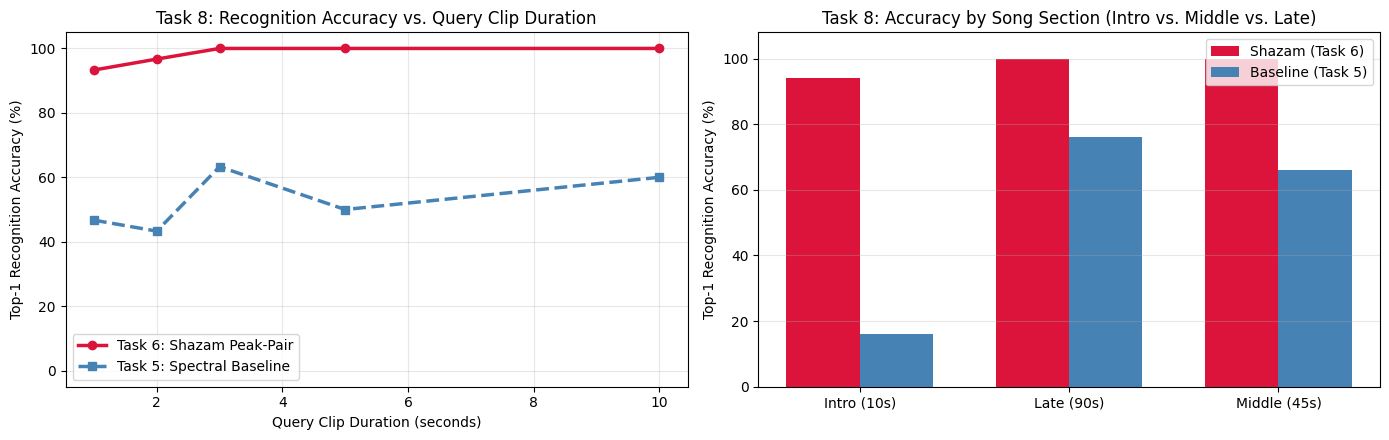

In [27]:
# ==============================================================================
# CELL 7: GROUP 3 — TASK 8: QUERY-LENGTH & STARTING-POSITION STUDY. Aniket
# ==============================================================================
# Plain English: Tests how short a clip can be (1s, 2s, 3s, 5s, 10s, 15s) and whether
# cutting the clip from the Intro (10s), Middle/Chorus (45s), or Outro (90s) changes
# how well Shazam (Task 6) and the Spectral Baseline (Task 5) recognize the song!

def evaluate_single_clip(query_y, sr, true_song_name):
    """Runs both Shazam (Task 6) and Baseline (Task 5) on a single audio array."""
    # 1. Shazam Peak-Pair Matcher
    q_peaks = get_peaks(query_y, sr=sr, cfg=FINAL_CFG)
    shazam_df = match_query(q_peaks, database, return_all_offsets=False)
    shazam_top = shazam_df.iloc[0]
    shazam_pred = shazam_top["Song Name"]
    shazam_score = int(shazam_top["Aligned Peak-Pair Votes (Score)"])
    shazam_correct = int(shazam_pred == true_song_name)

    # 2. Simple Spectral Baseline Matcher
    base_df = match_baseline_spectral(query_y, baseline_db)
    base_top = base_df.iloc[0]
    base_pred = base_top["Song Name"]
    base_sim = float(base_top["Cosine Similarity"])
    base_correct = int(base_pred == true_song_name)

    return {
        "shazam_correct": shazam_correct,
        "shazam_score": shazam_score,
        "shazam_pred": shazam_pred,
        "base_correct": base_correct,
        "base_sim": base_sim,
        "base_pred": base_pred,
        "n_peaks": len(q_peaks)
    }


def run_task8_experiment(eval_songs=None, durations=(1.0, 2.0, 3.0, 5.0, 10.0),
                         start_positions=(("Intro (10s)", 10.0), ("Middle (45s)", 45.0), ("Late (90s)", 90.0))):
    """Evaluates query durations and starting positions across songs in the database."""
    if eval_songs is None:
        # Use up to 10 songs by default so the full grid runs in ~45 seconds (set to NAMES for all songs)
        eval_songs = NAMES[:min(10, len(NAMES))]

    rows = []
    total_tests = len(eval_songs) * len(durations) * len(start_positions)
    test_idx = 0
    print(f"⏳ Running Task 8 Study across {len(eval_songs)} songs ({total_tests} total test clips)...")

    for s_name in eval_songs:
        s_path = SONG_MAP[s_name]
        # Load the full song once into RAM, slice all clips from it, then free RAM!
        full_y, sr = load_audio(s_path, target_sr=cfg["sr"])
        song_dur = len(full_y) / sr

        for pos_label, start_sec in start_positions:
            for d_sec in durations:
                test_idx += 1
                actual_start = max(0.0, min(start_sec, max(0.0, song_dur - d_sec - 1.0)))
                i0 = int(actual_start * sr)
                i1 = int((actual_start + d_sec) * sr)
                clip_y = full_y[i0:i1]

                res = evaluate_single_clip(clip_y, sr, s_name)
                rows.append({
                    "Song Name": s_name,
                    "Position": pos_label,
                    "Start (s)": round(actual_start, 1),
                    "Duration (s)": d_sec,
                    "Shazam Correct": res["shazam_correct"],
                    "Baseline Correct": res["base_correct"],
                    "Shazam Votes": res["shazam_score"],
                    "Baseline Cosine Sim": round(res["base_sim"], 4),
                    "Extracted Peaks": res["n_peaks"]
                })

        del full_y
        gc.collect()

    print("✅ Task 8 Experiment Complete!")
    return pd.DataFrame(rows)


# Run Task 8 and plot results
task8_df = run_task8_experiment()

# 1. Summary Table by Query Duration
dur_summary = (task8_df.groupby("Duration (s)")
               .agg(
                   Shazam_Accuracy_Pct=("Shazam Correct", lambda x: round(100 * np.mean(x), 1)),
                   Baseline_Accuracy_Pct=("Baseline Correct", lambda x: round(100 * np.mean(x), 1)),
                   Avg_Shazam_Votes=("Shazam Votes", lambda x: round(np.mean(x), 1)),
                   Avg_Baseline_Sim=("Baseline Cosine Sim", lambda x: round(np.mean(x), 4)),
                   Avg_Clip_Peaks=("Extracted Peaks", lambda x: round(np.mean(x), 1))
               ).reset_index())

# 2. Summary Table by Starting Position
pos_summary = (task8_df.groupby("Position")
               .agg(
                   Shazam_Accuracy_Pct=("Shazam Correct", lambda x: round(100 * np.mean(x), 1)),
                   Baseline_Accuracy_Pct=("Baseline Correct", lambda x: round(100 * np.mean(x), 1)),
                   Avg_Shazam_Votes=("Shazam Votes", lambda x: round(np.mean(x), 1))
               ).reset_index())

display(HTML("<h3>📏 Task 8A: Recognition Performance vs. Query Duration</h3>"))
display(dur_summary.style.hide(axis="index"))

display(HTML("<h3>⏱️ Task 8B: Recognition Performance vs. Starting Position</h3>"))
display(pos_summary.style.hide(axis="index"))

# 3. Plot Accuracy vs Duration & Accuracy Heatmap (Position x Duration)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left Plot: Line chart of Accuracy vs Query Length
axes[0].plot(dur_summary["Duration (s)"], dur_summary["Shazam_Accuracy_Pct"],
             marker="o", linewidth=2.5, color="crimson", label="Task 6: Shazam Peak-Pair")
axes[0].plot(dur_summary["Duration (s)"], dur_summary["Baseline_Accuracy_Pct"],
             marker="s", linewidth=2.5, linestyle="--", color="steelblue", label="Task 5: Spectral Baseline")
axes[0].set(title="Task 8: Recognition Accuracy vs. Query Clip Duration",
            xlabel="Query Clip Duration (seconds)", ylabel="Top-1 Recognition Accuracy (%)",
            ylim=(-5, 105))
axes[0].grid(alpha=0.3)
axes[0].legend()

# Right Plot: Bar chart by Starting Position
x_pos = np.arange(len(pos_summary))
width = 0.35
axes[1].bar(x_pos - width/2, pos_summary["Shazam_Accuracy_Pct"], width, color="crimson", label="Shazam (Task 6)")
axes[1].bar(x_pos + width/2, pos_summary["Baseline_Accuracy_Pct"], width, color="steelblue", label="Baseline (Task 5)")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(pos_summary["Position"])
axes[1].set(title="Task 8: Accuracy by Song Section (Intro vs. Middle vs. Late)",
            ylabel="Top-1 Recognition Accuracy (%)", ylim=(0, 108))
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()
plt.close(fig)

⏳ Running Task 9 Noise Robustness Study across 10 songs and 7 SNR levels...
✅ Task 9 Noise Study Complete!


SNR Label,Shazam_Accuracy_Pct,Baseline_Accuracy_Pct,Avg_Shazam_Votes,Avg_Baseline_Sim
Clean (∞ dB),100.000000,80.000000,228.500000,0.932000
+20 dB,100.000000,80.000000,195.000000,0.932500
+10 dB,100.000000,70.000000,108.000000,0.914300
+5 dB,100.000000,40.000000,65.900000,0.871000
+0 dB,100.000000,0.000000,37.700000,0.802100
-5 dB,100.000000,0.000000,18.900000,0.754400
-10 dB,100.000000,0.000000,9.200000,0.709500


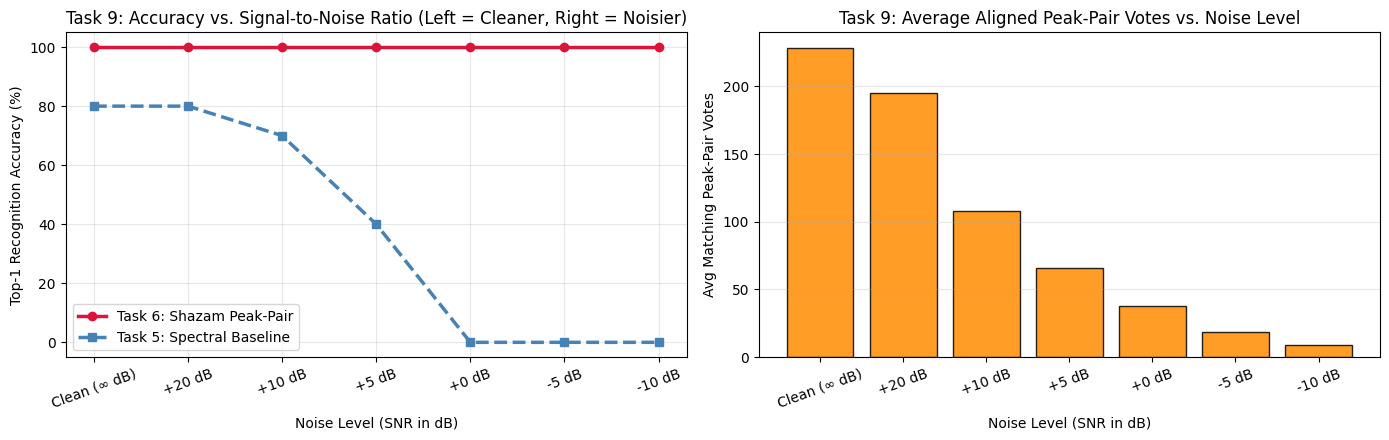

In [28]:
# ==============================================================================
# CELL 8: GROUP 3 — TASK 9: NOISE ROBUSTNESS STUDY (SNR IN DECIBELS). Aniket
# ==============================================================================
# Plain English: Tests how well Shazam and the Baseline Recognizer survive when we add
# synthetic white Gaussian noise at controlled Signal-to-Noise Ratios (SNR):
# Clean (No Noise), +20 dB (mild), +10 dB (moderate), 0 dB (noise = music power),
# -5 dB (noise louder than music), and -10 dB (extreme static).

def add_awgn_snr(y, snr_db, seed=42):
    """Adds White Gaussian Noise to signal `y` to achieve an exact target SNR (in dB)."""
    if snr_db is None or np.isinf(snr_db):
        return y.copy()
    rng = np.random.default_rng(seed)
    sig_power = np.mean(y ** 2) + 1e-12
    noise_power = sig_power / (10.0 ** (snr_db / 10.0))
    noise = rng.normal(0.0, np.sqrt(noise_power), size=len(y)).astype(np.float32)
    return y + noise


def run_task9_noise_study(eval_songs=None, snr_levels=(np.inf, 20, 10, 5, 0, -5, -10),
                          clip_start=40.0, clip_dur=5.0):
    """Tests recognition accuracy across multiple Signal-to-Noise Ratios (SNR in dB)."""
    if eval_songs is None:
        eval_songs = NAMES[:min(10, len(NAMES))]

    rows = []
    print(f"⏳ Running Task 9 Noise Robustness Study across {len(eval_songs)} songs and {len(snr_levels)} SNR levels...")

    for s_name in eval_songs:
        s_path = SONG_MAP[s_name]
        info = inspect_audio(s_path)
        actual_start = max(0.0, min(clip_start, max(0.0, info["orig_duration_s"] - clip_dur - 1.0)))
        clean_clip, sr = load_audio(s_path, target_sr=cfg["sr"], offset=actual_start, duration=clip_dur)

        for snr_db in snr_levels:
            noisy_clip = add_awgn_snr(clean_clip, snr_db)
            res = evaluate_single_clip(noisy_clip, sr, s_name)
            label = "Clean (∞ dB)" if np.isinf(snr_db) else f"{snr_db:+d} dB"

            rows.append({
                "Song Name": s_name,
                "SNR Label": label,
                "SNR (dB)": 30.0 if np.isinf(snr_db) else float(snr_db),
                "Shazam Correct": res["shazam_correct"],
                "Baseline Correct": res["base_correct"],
                "Shazam Votes": res["shazam_score"],
                "Baseline Cosine Sim": round(res["base_sim"], 4),
                "Extracted Peaks": res["n_peaks"]
            })

        del clean_clip
        gc.collect()

    print("✅ Task 9 Noise Study Complete!")
    return pd.DataFrame(rows)


task9_df = run_task9_noise_study()

noise_summary = (task9_df.groupby(["SNR (dB)", "SNR Label"], sort=False)
                 .agg(
                     Shazam_Accuracy_Pct=("Shazam Correct", lambda x: round(100 * np.mean(x), 1)),
                     Baseline_Accuracy_Pct=("Baseline Correct", lambda x: round(100 * np.mean(x), 1)),
                     Avg_Shazam_Votes=("Shazam Votes", lambda x: round(np.mean(x), 1)),
                     Avg_Baseline_Sim=("Baseline Cosine Sim", lambda x: round(np.mean(x), 4))
                 ).reset_index())

display(HTML("<h3>🔊 Task 9: Recognition Performance Under Additive White Noise (5s Clips)</h3>"))
display(noise_summary.drop(columns=["SNR (dB)"]).style.hide(axis="index"))

# Plot Accuracy & Aligned Votes vs SNR
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

x_labels = noise_summary["SNR Label"].tolist()
x_idx = np.arange(len(x_labels))

axes[0].plot(x_idx, noise_summary["Shazam_Accuracy_Pct"], marker="o", linewidth=2.5, color="crimson", label="Task 6: Shazam Peak-Pair")
axes[0].plot(x_idx, noise_summary["Baseline_Accuracy_Pct"], marker="s", linewidth=2.5, linestyle="--", color="steelblue", label="Task 5: Spectral Baseline")
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(x_labels, rotation=20)
axes[0].set(title="Task 9: Accuracy vs. Signal-to-Noise Ratio (Left = Cleaner, Right = Noisier)",
            xlabel="Noise Level (SNR in dB)", ylabel="Top-1 Recognition Accuracy (%)", ylim=(-5, 105))
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].bar(x_idx, noise_summary["Avg_Shazam_Votes"], color="darkorange", edgecolor="black", alpha=0.85)
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(x_labels, rotation=20)
axes[1].set(title="Task 9: Average Aligned Peak-Pair Votes vs. Noise Level",
            xlabel="Noise Level (SNR in dB)", ylabel="Avg Matching Peak-Pair Votes")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
plt.close(fig)

⏳ Running Task 10 Transformation Study (Time Stretch & Pitch Shift) across 8 songs...
✅ Task 10 Transformation Study Complete!


Stretch Rate,Shazam_Accuracy_Pct,Baseline_Accuracy_Pct,Avg_Shazam_Votes,Avg_Baseline_Sim
0.90x,87.500000,75.000000,6.600000,0.913100
0.95x,100.000000,75.000000,9.600000,0.914600
0.98x,100.000000,75.000000,20.100000,0.906600
1.00x,100.000000,75.000000,195.100000,0.919700
1.02x,100.000000,75.000000,48.900000,0.915400
1.05x,100.000000,75.000000,10.900000,0.908800
1.10x,87.500000,75.000000,6.600000,0.916900


Pitch Shift (Semitones),Shazam_Accuracy_Pct,Baseline_Accuracy_Pct,Avg_Shazam_Votes,Avg_Baseline_Sim
-2.0,25.000000,37.500000,3.200000,0.876600
-1.0,12.500000,50.000000,3.100000,0.869300
-0.5,25.000000,50.000000,4.000000,0.874200
+0.0,100.000000,75.000000,195.100000,0.919700
+0.5,12.500000,50.000000,3.200000,0.867400
+1.0,25.000000,12.500000,3.500000,0.856800
+2.0,0.000000,37.500000,3.600000,0.858700


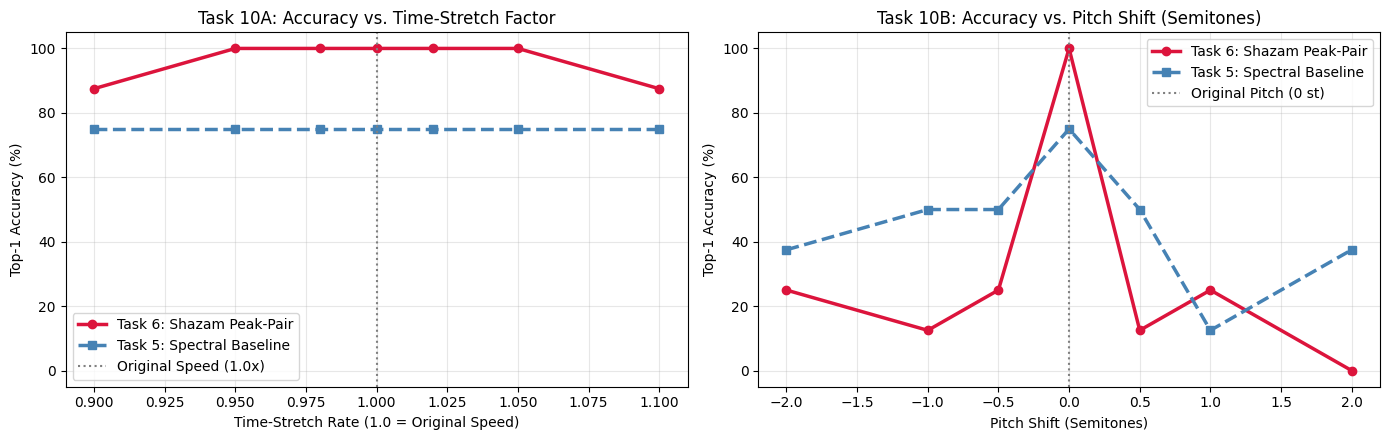

In [29]:
# ==============================================================================
# CELL 9: GROUP 3 — TASK 10: TRANSFORMATION ROBUSTNESS & METHOD COMPARISON. Aniket
# ==============================================================================
# Plain English: Tests two audio transformations that happen in real life:
#   1. Time Stretching (playing the song faster or slower: 0.90x, 0.95x, 0.98x, 1.0x, 1.02x, 1.05x, 1.10x)
#   2. Pitch Shifting (shifting notes up or down by semitones: -2, -1, -0.5, 0, +0.5, +1, +2)
# Compares where Shazam's exact Peak-Pair Hashing succeeds vs. where the Spectral Baseline
# holds up better!

def run_task10_transformation_study(eval_songs=None,
                                    stretch_rates=(0.90, 0.95, 0.98, 1.00, 1.02, 1.05, 1.10),
                                    pitch_steps=(-2.0, -1.0, -0.5, 0.0, 0.5, 1.0, 2.0),
                                    clip_start=40.0, clip_dur=5.0):
    if eval_songs is None:
        eval_songs = NAMES[:min(8, len(NAMES))]

    stretch_rows = []
    pitch_rows = []
    print(f"⏳ Running Task 10 Transformation Study (Time Stretch & Pitch Shift) across {len(eval_songs)} songs...")

    for s_name in eval_songs:
        s_path = SONG_MAP[s_name]
        info = inspect_audio(s_path)
        actual_start = max(0.0, min(clip_start, max(0.0, info["orig_duration_s"] - clip_dur - 1.0)))
        clean_clip, sr = load_audio(s_path, target_sr=cfg["sr"], offset=actual_start, duration=clip_dur)

        # 1. Time-Stretching Study
        for rate in stretch_rates:
            y_trans = clean_clip if rate == 1.0 else librosa.effects.time_stretch(clean_clip, rate=rate)
            res = evaluate_single_clip(y_trans, sr, s_name)
            stretch_rows.append({
                "Song Name": s_name,
                "Stretch Rate": f"{rate:.2f}x",
                "Rate Float": rate,
                "Shazam Correct": res["shazam_correct"],
                "Baseline Correct": res["base_correct"],
                "Shazam Votes": res["shazam_score"],
                "Baseline Cosine Sim": round(res["base_sim"], 4)
            })

        # 2. Pitch-Shifting Study
        for steps in pitch_steps:
            y_trans = clean_clip if steps == 0.0 else librosa.effects.pitch_shift(clean_clip, sr=sr, n_steps=steps)
            res = evaluate_single_clip(y_trans, sr, s_name)
            pitch_rows.append({
                "Song Name": s_name,
                "Pitch Shift (Semitones)": f"{steps:+.1f}",
                "Steps Float": steps,
                "Shazam Correct": res["shazam_correct"],
                "Baseline Correct": res["base_correct"],
                "Shazam Votes": res["shazam_score"],
                "Baseline Cosine Sim": round(res["base_sim"], 4)
            })

        del clean_clip
        gc.collect()

    print("✅ Task 10 Transformation Study Complete!")
    return pd.DataFrame(stretch_rows), pd.DataFrame(pitch_rows)


stretch_df, pitch_df = run_task10_transformation_study()

stretch_summary = (stretch_df.groupby(["Rate Float", "Stretch Rate"], sort=True)
                   .agg(
                       Shazam_Accuracy_Pct=("Shazam Correct", lambda x: round(100 * np.mean(x), 1)),
                       Baseline_Accuracy_Pct=("Baseline Correct", lambda x: round(100 * np.mean(x), 1)),
                       Avg_Shazam_Votes=("Shazam Votes", lambda x: round(np.mean(x), 1)),
                       Avg_Baseline_Sim=("Baseline Cosine Sim", lambda x: round(np.mean(x), 4))
                   ).reset_index())

pitch_summary = (pitch_df.groupby(["Steps Float", "Pitch Shift (Semitones)"], sort=True)
                 .agg(
                     Shazam_Accuracy_Pct=("Shazam Correct", lambda x: round(100 * np.mean(x), 1)),
                     Baseline_Accuracy_Pct=("Baseline Correct", lambda x: round(100 * np.mean(x), 1)),
                     Avg_Shazam_Votes=("Shazam Votes", lambda x: round(np.mean(x), 1)),
                     Avg_Baseline_Sim=("Baseline Cosine Sim", lambda x: round(np.mean(x), 4))
                 ).reset_index())

display(HTML("<h3>⏩ Task 10A: Time-Stretching Robustness (Speed Change Without Pitch Change)</h3>"))
display(stretch_summary.drop(columns=["Rate Float"]).style.hide(axis="index"))

display(HTML("<h3>🎹 Task 10B: Pitch-Shifting Robustness (Key Change Without Speed Change)</h3>"))
display(pitch_summary.drop(columns=["Steps Float"]).style.hide(axis="index"))

# Plot Side-by-Side Comparison: Time Stretch vs Pitch Shift
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(stretch_summary["Rate Float"], stretch_summary["Shazam_Accuracy_Pct"],
             marker="o", linewidth=2.5, color="crimson", label="Task 6: Shazam Peak-Pair")
axes[0].plot(stretch_summary["Rate Float"], stretch_summary["Baseline_Accuracy_Pct"],
             marker="s", linewidth=2.5, linestyle="--", color="steelblue", label="Task 5: Spectral Baseline")
axes[0].axvline(1.0, color="gray", linestyle=":", label="Original Speed (1.0x)")
axes[0].set(title="Task 10A: Accuracy vs. Time-Stretch Factor",
            xlabel="Time-Stretch Rate (1.0 = Original Speed)", ylabel="Top-1 Accuracy (%)", ylim=(-5, 105))
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(pitch_summary["Steps Float"], pitch_summary["Shazam_Accuracy_Pct"],
             marker="o", linewidth=2.5, color="crimson", label="Task 6: Shazam Peak-Pair")
axes[1].plot(pitch_summary["Steps Float"], pitch_summary["Baseline_Accuracy_Pct"],
             marker="s", linewidth=2.5, linestyle="--", color="steelblue", label="Task 5: Spectral Baseline")
axes[1].axvline(0.0, color="gray", linestyle=":", label="Original Pitch (0 st)")
axes[1].set(title="Task 10B: Accuracy vs. Pitch Shift (Semitones)",
            xlabel="Pitch Shift (Semitones)", ylabel="Top-1 Accuracy (%)", ylim=(-5, 105))
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()
plt.close(fig)

In [30]:
# ==============================================================================
# CELL 10: GROUP 3 — INTERACTIVE TRANSFORMATION & ROBUSTNESS TORTURE-TEST LAB. Aniket
# ==============================================================================
# Plain English: Bonus interactive explorer for Group 3! Pick any song, apply live
# White Noise (SNR dB), Pitch Shifting (semitones), and Time Stretching (speed),
# listen to the distorted clip, and see side-by-side why one recognizer succeeds or fails!

g3_song = widgets.Dropdown(
    options=[(f"[{i+1:2d}] {name}", name) for i, name in enumerate(NAMES)],
    value=NAMES[0],
    description="🎵 Song:",
    style={"description_width": "110px"},
    layout=widgets.Layout(width="450px")
)
g3_dur = widgets.FloatSlider(value=5.0, min=1.0, max=12.0, step=1.0, description="📏 Clip (s):", style={"description_width": "110px"})
g3_snr = widgets.SelectionSlider(
    options=[("Clean", np.inf), ("+20 dB", 20.0), ("+10 dB", 10.0), ("0 dB", 0.0), ("-5 dB", -5.0), ("-10 dB", -10.0)],
    value=np.inf,
    description="🔊 Noise SNR:",
    style={"description_width": "110px"}
)
g3_stretch = widgets.FloatSlider(value=1.00, min=0.85, max=1.15, step=0.01, description="⏩ Speed:", style={"description_width": "110px"})
g3_pitch = widgets.FloatSlider(value=0.0, min=-3.0, max=3.0, step=0.5, description="🎹 Pitch (st):", style={"description_width": "110px"})
g3_btn = widgets.Button(description="🧪 Run Torture Test!", button_style="warning", layout=widgets.Layout(width="220px", height="38px"))
g3_out = widgets.Output()

def on_g3_test(_):
    with g3_out:
        clear_output(wait=True)
        s_name = g3_song.value
        s_path = SONG_MAP[s_name]
        clip_y, sr = load_audio(s_path, target_sr=cfg["sr"], offset=35.0, duration=g3_dur.value)

        # Apply transformations in order: Time Stretch -> Pitch Shift -> Additive Noise
        if g3_stretch.value != 1.0:
            clip_y = librosa.effects.time_stretch(clip_y, rate=g3_stretch.value)
        if g3_pitch.value != 0.0:
            clip_y = librosa.effects.pitch_shift(clip_y, sr=sr, n_steps=g3_pitch.value)
        if not np.isinf(g3_snr.value):
            clip_y = add_awgn_snr(clip_y, g3_snr.value)

        res = evaluate_single_clip(clip_y, sr, s_name)
        s_ok = "✅ PASS" if res["shazam_correct"] else "❌ FAIL"
        b_ok = "✅ PASS" if res["base_correct"] else "❌ FAIL"

        display(HTML(f"""
        <div style="border: 2px solid #555; background: #f8f9fa; padding: 14px; border-radius: 8px; color: #111;">
            <h4 style="margin-top:0;">🧪 Group 3 Torture-Test Verdict on: <b>{s_name}</b></h4>
            <ul>
                <li><b>Task 6 Shazam Peak-Pair Matcher:</b> {s_ok} — Predicted: <b>{res['shazam_pred']}</b> ({res['shazam_score']} aligned votes)</li>
                <li><b>Task 5 Simple Spectral Baseline:</b> {b_ok} — Predicted: <b>{res['base_pred']}</b> (Cosine Sim: {res['base_sim']:.4f})</li>
            </ul>
        </div>
        """))
        display(Audio(clip_y, rate=sr))
        del clip_y
        gc.collect()

g3_btn.on_click(on_g3_test)
display(HTML("<h3>🧪 Group 3 Interactive Transformation & Noise Torture-Test Lab</h3>"))
display(widgets.VBox([
    widgets.HBox([g3_song, g3_btn]),
    widgets.HBox([g3_dur, g3_snr]),
    widgets.HBox([g3_stretch, g3_pitch])
]), g3_out)
on_g3_test(None)

Output()